# Part A: House Price Prediction (Regression)
Dataset: Egypt Houses Price (Kaggle). Target: `Price` (EGP).
Models: Linear Regression and KNN Regressor. Split: 70% train / 15% validation / 15% test (`random_state=42`).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42                           # same seed everywhere, so results can be repeated
pd.set_option("display.max_columns", 50)    # show every column
sns.set_theme(style="whitegrid")            # one clean plot style for the whole notebook

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.7.1


In [7]:
df = pd.read_csv("data/Egypt_Houses_Price.csv")

# Remove stray spaces around every value, e.g. "Unknown " -> "Unknown" and "Silva " -> "Silva"
for col in df.columns:
    df[col] = df[col].str.strip()

print(df.shape)
df.head()

(27361, 12)


,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
0,Duplex,4000000,3.0,3.0,400.0,No,7,Unknown,Cash,Ready to move,Finished,Nasr City
1,Apartment,4000000,3.0,3.0,160.0,No,10+,Unknown,Cash,Ready to move,Finished,Camp Caesar
2,Apartment,2250000,3.0,2.0,165.0,No,1,Unknown,Cash,Ready to move,Finished,Smoha
3,Apartment,1900000,3.0,2.0,230.0,No,10,Unknown,Cash,Ready to move,Finished,Nasr City
4,Apartment,5800000,2.0,3.0,160.0,No,Ground,Eastown,Cash,Ready to move,Semi Finished,New Cairo - El Tagamoa


### Where is data missing?

In [8]:
# Two kinds of missing: real empty cells (NaN) and the placeholder word "Unknown"
audit = pd.DataFrame({
    "nulls":   df.isna().sum(),
    "unknown": (df == "Unknown").sum(),
})
audit["pct_missing"] = ((audit["nulls"] + audit["unknown"]) / len(df) * 100).round(1)
audit.sort_values("pct_missing", ascending=False)

,nulls,unknown,pct_missing
Compound,0,11068,40.5
Level,0,10439,38.2
Delivery_Date,0,10108,36.9
Furnished,0,8528,31.2
Delivery_Term,0,4706,17.2
Area,471,36,1.9
Bedrooms,203,36,0.9
Bathrooms,171,36,0.8
Type,0,36,0.1
Price,2,37,0.1


In [9]:
# How many missing fields does each row have?
missing_per_row = (df == "Unknown").sum(axis=1) + df.isna().sum(axis=1)
missing_per_row.value_counts().sort_index()

0     5086
1     8931
2     6673
3     4103
4     1834
5      627
6       39
7       30
8        2
10      36
Name: count, dtype: int64

### Cleaning

In [10]:
print("Rows at start:", len(df))

# 1. Junk rows: scraper leftovers where every field is "Unknown" (not real houses)
df = df[df["Price"] != "Unknown"].copy()
print("After removing junk rows:", len(df))

# 2. Make the number columns real numbers (one value in Bedrooms and Bathrooms is "10+", we use 10)
for col in ["Price", "Bedrooms", "Bathrooms", "Area"]:
    df[col] = pd.to_numeric(df[col].replace("10+", "10"))

# 3. Merge spellings of the same type: "Twin house" -> "Twin House", "Stand Alone Villa" -> "Standalone Villa"
df["Type"] = df["Type"].str.title().replace("Stand Alone Villa", "Standalone Villa")

# 4. Remove rows with no Price (it is the target, we cannot learn from a house with no answer)
df = df.dropna(subset=["Price"])
print("After removing rows with no Price:", len(df))

# 5. Remove exact duplicates (done AFTER steps 2-3, so "3" and "3.0" now count as the same value)
before = len(df)
df = df.drop_duplicates()
print("Duplicates removed:", before - len(df))

# 6. Remove impossible values: prices under 100,000 EGP and areas under 20 m²
before = len(df)
df = df[df["Price"] >= 100_000]
print("Prices under 100,000 removed:", before - len(df))

before = len(df)
df = df[df["Area"].isna() | (df["Area"] >= 20)]   # keep empty Areas, we fill them later
print("Areas under 20 removed:", before - len(df))

df = df.reset_index(drop=True)
print("Final shape:", df.shape)

Rows at start: 27361
After removing junk rows: 27324
After removing rows with no Price: 27322
Duplicates removed: 1896
Prices under 100,000 removed: 56
Areas under 20 removed: 4
Final shape: (25366, 12)


In [11]:
df[["Price", "Bedrooms", "Bathrooms", "Area"]].describe().round(0)

,Price,Bedrooms,Bathrooms,Area
count,25366.0,25167.0,25199.0,24904.0
mean,4847392.0,3.0,3.0,231.0
std,6911355.0,1.0,1.0,162.0
min,100000.0,1.0,1.0,20.0
25%,1150000.0,3.0,2.0,125.0
50%,2800000.0,3.0,3.0,178.0
75%,6000000.0,4.0,4.0,276.0
max,240000000.0,10.0,10.0,998.0


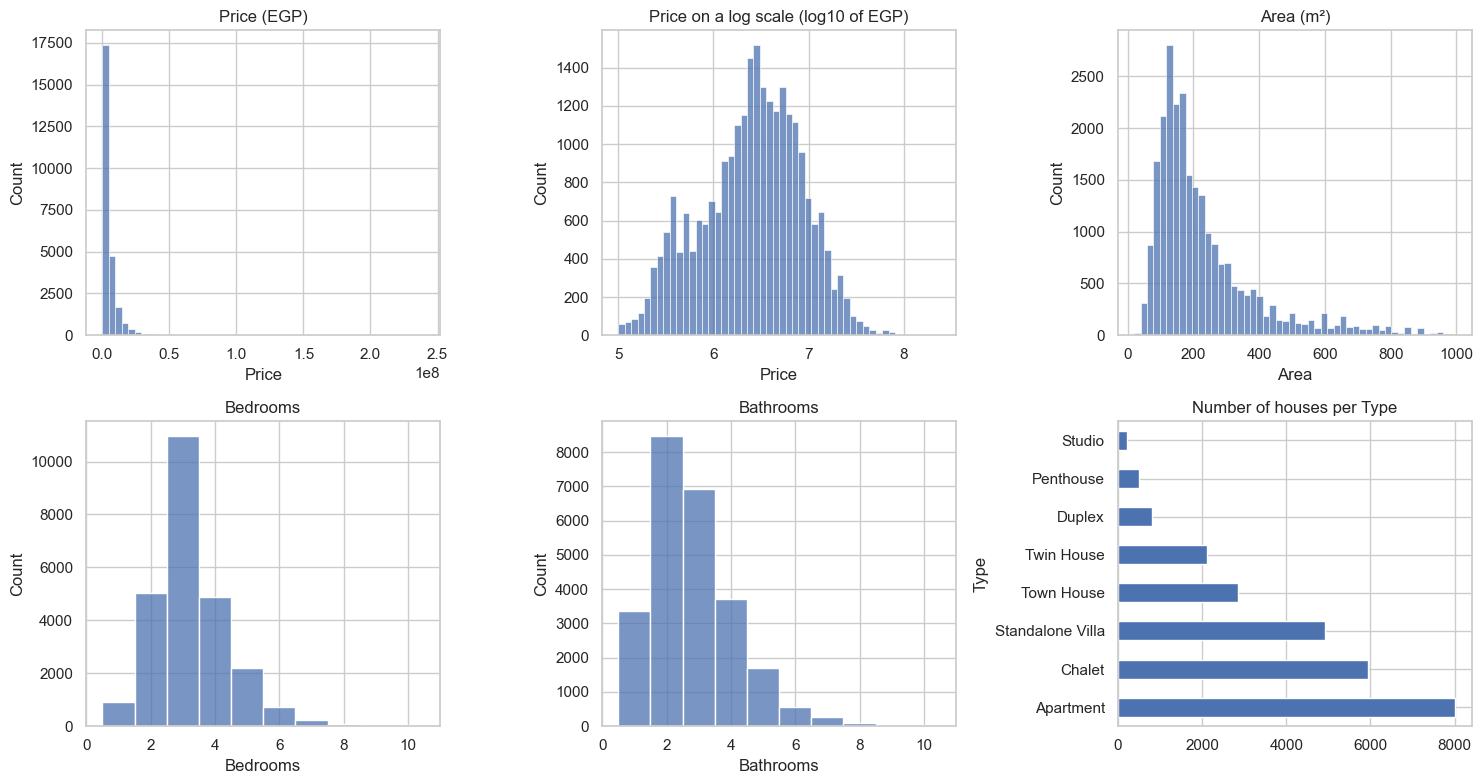

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

sns.histplot(df["Price"], bins=50, ax=axes[0, 0])
axes[0, 0].set_title("Price (EGP)")

sns.histplot(np.log10(df["Price"]), bins=50, ax=axes[0, 1])
axes[0, 1].set_title("Price on a log scale (log10 of EGP)")

sns.histplot(df["Area"], bins=50, ax=axes[0, 2])
axes[0, 2].set_title("Area (m²)")

sns.histplot(df["Bedrooms"], discrete=True, ax=axes[1, 0])
axes[1, 0].set_title("Bedrooms")

sns.histplot(df["Bathrooms"], discrete=True, ax=axes[1, 1])
axes[1, 1].set_title("Bathrooms")

df["Type"].value_counts().plot.barh(ax=axes[1, 2])
axes[1, 2].set_title("Number of houses per Type")

plt.tight_layout()
plt.show()

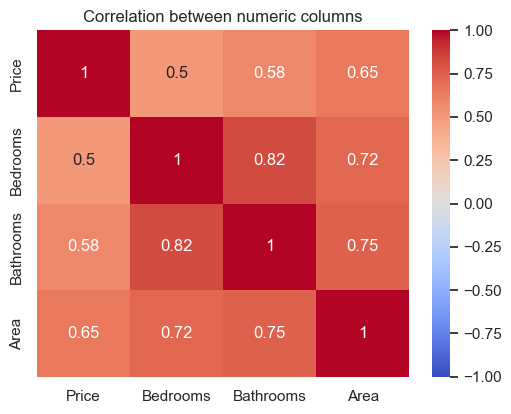

In [13]:
corr = df[["Price", "Bedrooms", "Bathrooms", "Area"]].corr()

plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric columns")
plt.show()

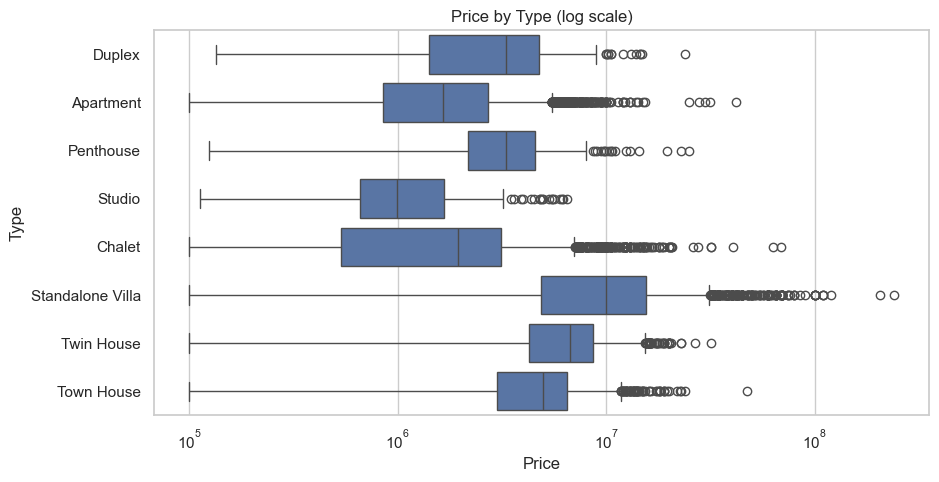

In [14]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Price", y="Type")
plt.xscale("log")          # log scale, otherwise the expensive houses squash everything else
plt.title("Price by Type (log scale)")
plt.show()

## Suspiciously cheap listings
Some prices look too low for the size of the house. We check price per m² and how the payment option is spread across price bands.

In [15]:
# Price per m². We keep it as a separate Series and NOT as a new column of df,
# because it is made from Price (the target) and would leak the answer into the features.
price_per_m2 = df["Price"] / df["Area"]

cheap = df[price_per_m2 < 1000]          # under 1,000 EGP per m²
print("Suspiciously cheap listings:", len(cheap))

print(cheap["Payment_Option"].value_counts())    # the cheap ones
print(df["Payment_Option"].value_counts())       # all houses, for comparison

cheap[["Type", "Price", "Area", "City", "Payment_Option"]].head(10)

Suspiciously cheap listings: 158
Payment_Option
Cash or Installment    71
Installment            50
Unknown Payment        31
Cash                    6
Name: count, dtype: int64
Payment_Option
Cash or Installment    9858
Cash                   8987
Installment            3638
Unknown Payment        2883
Name: count, dtype: int64


,Type,Price,Area,City,Payment_Option
614,Apartment,125800.0,180.0,6th of October,Installment
776,Apartment,110000.0,121.0,New Cairo - El Tagamoa,Cash or Installment
975,Apartment,129000.0,130.0,6th of October,Unknown Payment
1083,Apartment,110000.0,120.0,Nasr City,Cash
1215,Apartment,123000.0,165.0,Mostakbal City,Installment
1222,Apartment,122000.0,147.0,Mostakbal City,Installment
1234,Apartment,124000.0,141.0,Nasr City,Installment
1475,Duplex,324000.0,378.0,New Capital City,Installment
1725,Duplex,216000.0,270.0,New Capital City,Cash or Installment
1958,Apartment,123000.0,134.0,New Capital City,Installment


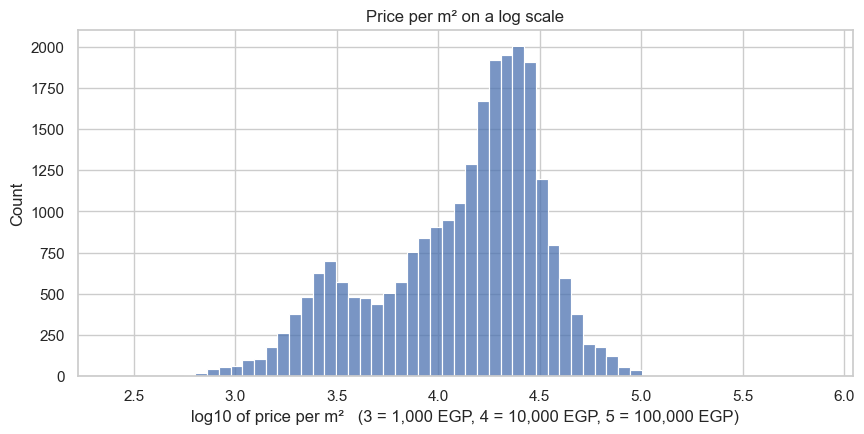

In [16]:
price_per_m2 = df["Price"] / df["Area"]      # separate Series, not a column of df (it is made from the target)
log_ppm = np.log10(price_per_m2.dropna())

plt.figure(figsize=(10, 4.5))
sns.histplot(log_ppm, bins=60)
plt.xlabel("log10 of price per m²   (3 = 1,000 EGP, 4 = 10,000 EGP, 5 = 100,000 EGP)")
plt.title("Price per m² on a log scale")
plt.show()

In [17]:
# How are the payment options spread across price-per-m² bands?
band = pd.cut(price_per_m2, [0, 1000, 2000, 3000, 4000, 5000, 7500, 10000, 20000, 1e9])
print(band.value_counts().sort_index())
pd.crosstab(band, df["Payment_Option"], normalize="index").round(2)

(0.0, 1000.0]               169
(1000.0, 2000.0]            901
(2000.0, 3000.0]           1743
(3000.0, 4000.0]           1190
(4000.0, 5000.0]            807
(5000.0, 7500.0]           1712
(7500.0, 10000.0]          1874
(10000.0, 20000.0]         6901
(20000.0, 1000000000.0]    9607
Name: count, dtype: int64


Payment_Option,Cash,Cash or Installment,Installment,Unknown Payment
row_0,,,,
"(0.0, 1000.0]",0.04,0.46,0.30,0.20
"(1000.0, 2000.0]",0.05,0.61,0.17,0.17
"(2000.0, 3000.0]",0.08,0.74,0.05,0.13
"(3000.0, 4000.0]",0.15,0.66,0.06,0.13
"(4000.0, 5000.0]",0.31,0.50,0.07,0.12
"(5000.0, 7500.0]",0.40,0.38,0.12,0.11
"(7500.0, 10000.0]",0.44,0.35,0.11,0.10
"(10000.0, 20000.0]",0.45,0.30,0.14,0.11
"(20000.0, 1000000000.0]",0.36,0.35,0.19,0.11


### What the data shows

I took price per m² on a log scale (the scale where it’s closest to a bell shape) and checked the payment mix in each price band.

It isn’t one bell. There’s a second, smaller hump around 2,000–3,000 EGP/m², then a dip near 4,000, and then the main hill, which peaks around 15,000–25,000.
The payment mix changes at the same spot. Below about 4,000 EGP/m², 72–81% of the houses are Installment or Cash or Installment and only 3–15% are Cash. From 5,000 EGP/m² upward, installments drop to about 44–49% and cash rises to 31–45%.
So the suspicious group is not just the 158 rows under 1,000. It’s roughly 4,000 rows (about 16%) below the dip.

### Three Options for Handling Price Outliers

| Option | Rule | Rows Removed | Trade-off |
|:---:|---|---:|---|
| **1** | Keep everything (only apply the 100,000 EGP price floor). | 0 | Simplest approach, but results in the noisiest target distribution. |
| **2** | **1.5 × IQR rule on log price per m²**, allowing values between 1,076 and 167,418 EGP/m². | 219 (0.9%) | Objective and statistically standard, but only trims the extreme tail. |
| **3** | Cut at the distribution's dip, approximately 4,000 EGP/m². | ~4,000 (16%) | Targets the broader cluster of unusually cheap listings, but risks removing genuinely affordable properties and teaching the model that cheap houses don't exist. |

### Decision: remove extreme price-per-m² values
We keep prices within the 1.5 x IQR range on the log scale (1,076 to 167,418 EGP per m²), which removes 219 rows.
Known limitation: a larger cluster of cheap listings (about 1,000 to 4,000 EGP per m²) remains. Most of them are installment listings, so their price may be a down payment, and the models will probably make large errors on them.

In [18]:
# 1.5 x IQR rule on the log scale (the same idea as the box plot, on the scale where the data is bell-shaped)
q1, q3 = log_ppm.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = 10 ** (q1 - 1.5 * iqr), 10 ** (q3 + 1.5 * iqr)
print(f"Allowed price per m²: {low:,.0f} to {high:,.0f} EGP")

keep = price_per_m2.isna() | ((price_per_m2 >= low) & (price_per_m2 <= high))   # keep rows with empty Area
print("Rows removed:", (~keep).sum())

df = df[keep].reset_index(drop=True)
print("Final shape:", df.shape)

Allowed price per m²: 1,076 to 167,418 EGP
Rows removed: 219
Final shape: (25147, 12)


In [19]:
X = df.drop(columns="Price")     # features: everything except the answer
y = df["Price"]                  # target: what we want to predict

# First take 70% for training, then split the remaining 30% in half: 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE)

print("Train:", len(X_train), " Validation:", len(X_val), " Test:", len(X_test))

Train: 17602  Validation: 3772  Test: 3773


In [20]:
numeric_cols = ["Bedrooms", "Bathrooms", "Area"]
categorical_cols = ["Type", "Furnished", "Level", "Compound", "Payment_Option",
                    "Delivery_Date", "Delivery_Term", "City"]

# Numbers: fill empty cells with the median, add a 0/1 "was missing" column, then scale
numeric_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])

# Categories: one 0/1 column per category.
# Categories with fewer than 50 houses in the training data are grouped into one "infrequent" column.
categorical_step = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)

preprocess = ColumnTransformer([
    ("numeric", numeric_steps, numeric_cols),
    ("categorical", categorical_step, categorical_cols),
])

In [21]:
X_train_ready = preprocess.fit_transform(X_train)    # learns medians, scaling and categories from TRAIN only
print("Before:", X_train.shape, " After:", X_train_ready.shape)

names = list(preprocess.get_feature_names_out())
print(names[:8])
print(names[-6:])

Before: (17602, 11)  After: (17602, 124)
['numeric__Bedrooms', 'numeric__Bathrooms', 'numeric__Area', 'numeric__missingindicator_Bedrooms', 'numeric__missingindicator_Bathrooms', 'numeric__missingindicator_Area', 'categorical__Type_Apartment', 'categorical__Type_Chalet']
['categorical__City_Rehab City', 'categorical__City_Sheikh Zayed', 'categorical__City_Shorouk City', 'categorical__City_Smoha', 'categorical__City_Zahraa Al Maadi', 'categorical__City_infrequent_sklearn']


### Why These Preprocessing Choices?

- **Median, not mean, for missing numerical values.** The median is less affected by extreme values. The *missingness indicator* columns preserve information about which values were originally empty. This matters particularly for villas, which have the highest frequency of missing `Area` values.

- **Scaling** puts `Area` (ranging from 20 to 998) on a comparable scale with the 0/1 encoded columns. KNN needs scaling because it relies on distances, as my testing demonstrated. Linear Regression can also work with scaled features.

- **`min_frequency=50`** handles high-cardinality categorical columns without requiring additional manual encoding. `City` has 178 unique values and `Compound` has 559, but in my run, only 26 cities and 48 compounds receive their own columns. The remaining less-frequent categories are grouped into an `"infrequent"` category.

In [22]:
# A Pipeline chains the steps: preprocessing first, then the model.
# fit() learns everything from the training data; predict() applies the same steps to new houses.
linreg = Pipeline([("preprocess", preprocess), ("model", LinearRegression())])
linreg.fit(X_train, y_train)

val_pred = linreg.predict(X_val)

print("Linear Regression on the validation set")
print("MAE :", round(mean_absolute_error(y_val, val_pred)))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, val_pred))))
print("R²  :", round(r2_score(y_val, val_pred), 3))
print("Negative predicted prices:", (val_pred < 0).sum(), "of", len(val_pred))

Linear Regression on the validation set
MAE : 2251299
RMSE: 4671658
R²  : 0.569
Negative predicted prices: 223 of 3772


 k       MAE      RMSE    R2
 1 2205584.0 5525970.0 0.397
 3 2060530.0 4730364.0 0.558
 5 2030657.0 4652009.0 0.573
 7 2030843.0 4634801.0 0.576
 9 2005777.0 4613751.0 0.580
11 2005978.0 4619533.0 0.579
15 2029344.0 4609834.0 0.581
21 2027020.0 4589720.0 0.584
31 2041425.0 4588611.0 0.584
41 2063920.0 4611458.0 0.580
51 2077492.0 4603475.0 0.582


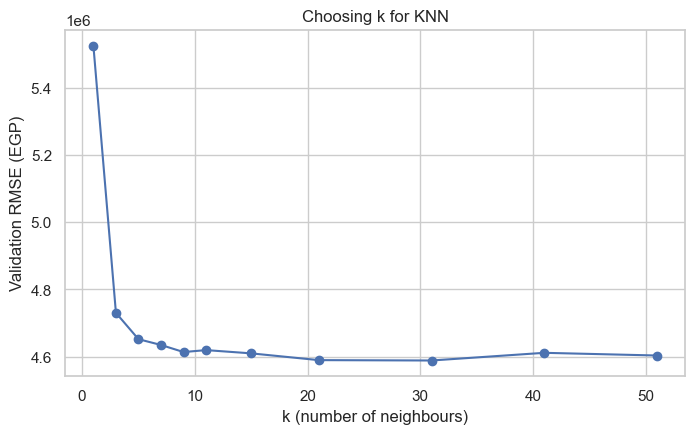

In [23]:
# For each k: fit on the training set, measure the error on the VALIDATION set
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51]
rows = []

for k in k_values:
    knn = Pipeline([("preprocess", preprocess), ("model", KNeighborsRegressor(n_neighbors=k))])
    knn.fit(X_train, y_train)
    pred = knn.predict(X_val)
    rows.append([k,
                 mean_absolute_error(y_val, pred),
                 np.sqrt(mean_squared_error(y_val, pred)),
                 r2_score(y_val, pred)])

results = pd.DataFrame(rows, columns=["k", "MAE", "RMSE", "R2"])
print(results.round({"MAE": 0, "RMSE": 0, "R2": 3}).to_string(index=False))

plt.figure(figsize=(8, 4.5))
plt.plot(results["k"], results["RMSE"], marker="o")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Validation RMSE (EGP)")
plt.title("Choosing k for KNN")
plt.show()

In [24]:
best_k = int(results.loc[results["RMSE"].idxmin(), "k"])    # k with the lowest validation RMSE
print("Best k by RMSE:", best_k)

Best k by RMSE: 31


### KNN Hyperparameter Selection and Observations

The KNN model was evaluated using different values of *k*, representing the number of nearest neighbors considered when predicting a property's price.

With k=1, the model performed relatively poorly, likely because relying on a single neighboring listing makes predictions sensitive to individual observations and pricing noise. Increasing the number of neighbors generally improved performance by producing more stable predictions.

The lowest validation RMSE was achieved at **k=31**, with an RMSE of approximately 4.59 million EGP, an MAE of approximately 2.04 million EGP, and an R² of 0.584.

MAE reached its lowest value at k=9, while RMSE and R² favored k=31. Since RMSE was selected as the primary model-selection metric, k=31 was retained for subsequent comparisons.

The performance differences across larger values of k were relatively small, suggesting that the model is not particularly sensitive to the exact choice within this range.

Linear Regression also produced negative price predictions for 223 out of 3,772 validation observations (approximately 5.9%). This is a limitation of unconstrained linear predictions and may be investigated through log-transformed target regression in a later experiment.